<a href="https://colab.research.google.com/github/NAITIk0908/NumPy-Image-Processing-Toolkit/blob/main/numpy_image_toolkit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1.built-in image

shape: (427, 640, 3)
dtype: uint8
min/max: 0 255


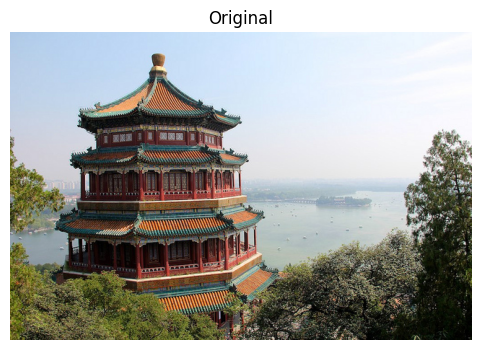

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg")

print("shape:", img.shape)
print("dtype:", img.dtype)
print("min/max:", img.min(), img.max())

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.show()

## 2. Grayscale, flip and rotate



In [2]:

weights = np.array([0.299, 0.587, 0.114])
gray = (img * weights).sum(axis=2)
gray = gray.astype(np.uint8)



flip_ud = img[::-1]
flip_lr = img[:, ::-1]


rot_cw  = img.transpose(1, 0, 2)[:, ::-1]
rot_ccw = img.transpose(1, 0, 2)[::-1]
rot_180 = img[::-1, ::-1]


assert np.array_equal(rot_ccw, np.rot90(img, k=1))
assert np.array_equal(rot_cw,  np.rot90(img, k=-1))
assert np.array_equal(rot_180, np.rot90(img, k=2))

print("gray:", gray.shape, "| rot_cw:", rot_cw.shape)

gray: (427, 640) | rot_cw: (640, 427, 3)


## 3. Split channels



In [3]:
R, G, B = img[..., 0], img[..., 1], img[..., 2]

def tint(channel_index):
    """Return an RGB image that keeps only one channel."""
    out = np.zeros_like(img)
    out[..., channel_index] = img[..., channel_index]
    return out

red_img, green_img, blue_img = tint(0), tint(1), tint(2)


merged = np.stack([R, G, B], axis=-1)
assert np.array_equal(merged, img)


gray_rgb = np.stack([gray] * 3, axis=-1)


top    = np.hstack([img, gray_rgb, flip_lr])
bottom = np.hstack([red_img, green_img, blue_img])
collage = np.vstack([top, bottom])

print("collage shape:", collage.shape)

collage shape: (854, 1920, 3)


## 4.  results  

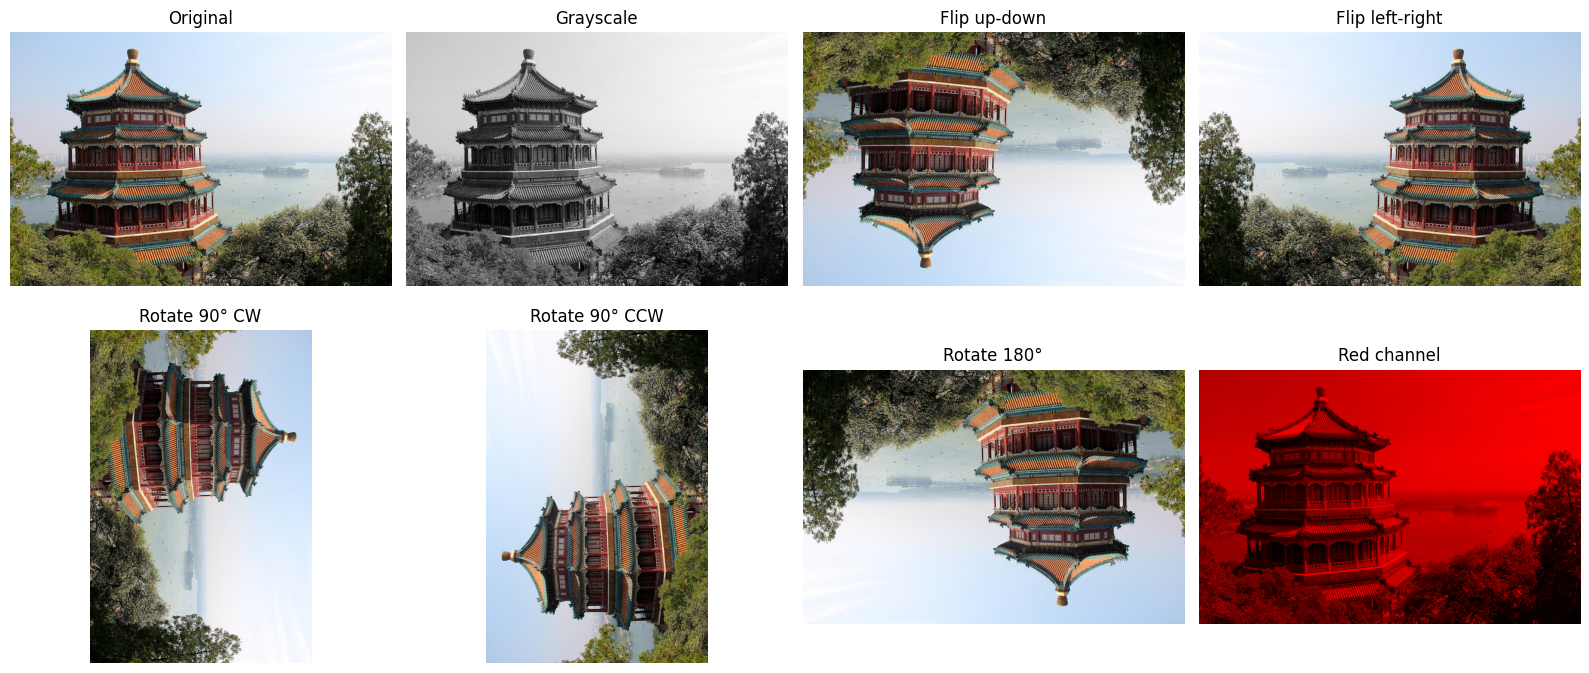

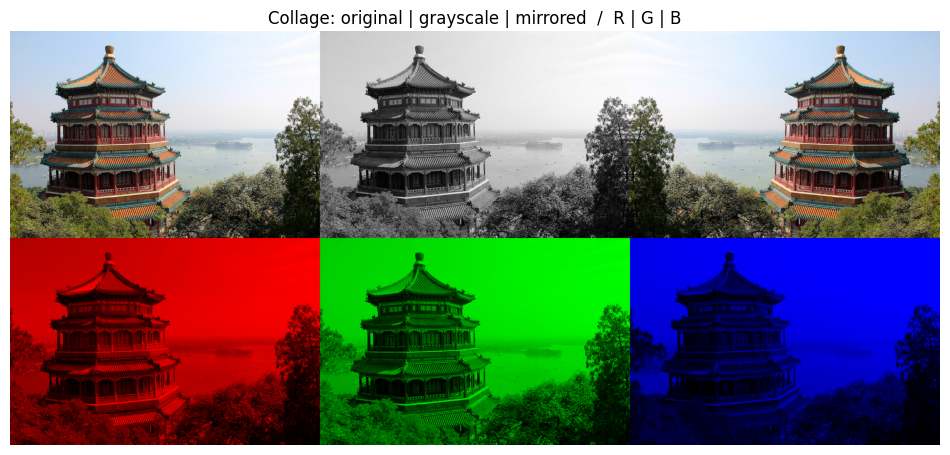

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
panels = [
    (img, "Original"), (gray, "Grayscale"), (flip_ud, "Flip up-down"), (flip_lr, "Flip left-right"),
    (rot_cw, "Rotate 90° CW"), (rot_ccw, "Rotate 90° CCW"), (rot_180, "Rotate 180°"), (red_img, "Red channel"),
]
for ax, (im, title) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(collage)
plt.title("Collage: original | grayscale | mirrored  /  R | G | B")
plt.axis("off")
plt.show()

### Vectorised vs pixel loops



In [5]:
def gray_numpy(a):
    return (a @ weights).astype(np.uint8)

def gray_loop(a):
    h, w, _ = a.shape
    out = np.empty((h, w), dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            out[i, j] = 0.299 * a[i, j, 0] + 0.587 * a[i, j, 1] + 0.114 * a[i, j, 2]
    return out

assert np.abs(gray_numpy(img).astype(int) - gray_loop(img).astype(int)).max() <= 1

In [6]:
%timeit gray_numpy(img)

1.56 ms ± 260 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [7]:
%timeit -n 1 -r 3 gray_loop(img)

1.88 s ± 13.4 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


**Takeaway:** the vectorised version is typically hundreds to thousands of times faster, and the same pattern (slice, transpose, broadcast, stack) covers every other operation in this notebook.